# VaR y ES de una cartera: convención de signos, simulación histórica y un primer conteo de excepciones

- **Nivel:** 1, Fundamentos
- **Requisitos previos:** el notebook 01 del tema 01 (instalar y abrir un artefacto)
- **Tiempo de lectura:** unos 30 minutos

**Pregunta:** En los 251 días hábiles del año de crisis de 2008, ¿cuántas veces falló un valor en riesgo a un día al 99 por ciento de una posición en euros, y es ese conteo compatible con un pronóstico correcto?

## Objetivos

Al terminar este notebook puedes:

- enunciar las dos convenciones de signos del riesgo de mercado, decir cuál guarda el motor y cuál usan los documentos versionados, y convertir entre ellas con la función del propio motor;
- calcular un valor en riesgo (VaR) y una pérdida esperada (ES) a partir de una muestra de retornos, y decir en cuántas observaciones se apoya de verdad la estimación de la cola;
- producir un pronóstico de simulación histórica a un paso que no usa información del día pronosticado ni posterior;
- contar las excepciones de un pronóstico de VaR, compararlas con las esperadas y leer la prueba de proporción de fallas de Kupiec;
- reconstruir las banderas de excepción de un pronóstico versionado, incluso en una ventana cuyos retornos realizados no se versionan.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas, imprimir las versiones con que corren y fijar las palabras que este notebook
# imprime para las luces del motor
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

LIGHT = {"green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada"}

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Los datos son el caso C11 (pronóstico y prueba retrospectiva de VaR y ES) tal como Contraste lo versiona. Se leen dos archivos.

- `data/derived/C11/fx-2008.json`: una posición larga en el euro frente al dólar de EE. UU., de julio de 2008 a junio de 2009, 251 días de pronóstico. Los retornos diarios son el cambio simple del tipo de cambio H.10 de la Reserva Federal (clase de licencia `mirror-allowed`), así que el archivo **versiona las pérdidas realizadas**. Es el archivo donde cada número de este notebook se puede recalcular desde los retornos.
- `data/derived/C11/calm-2004-06.json`: una cartera mixta (50 por ciento renta variable de EE. UU., 30 por ciento bono del Tesoro a 10 años, 20 por ciento euro) en los años tranquilos 2004 a 2006, 750 días de pronóstico. Uno de sus componentes es el retorno accionario de Kenneth French, una fuente **solo derivada**: el archivo guarda los pronósticos de los 17 modelos y sus días de excepción, y retiene las pérdidas realizadas.

Los dos archivos llevan los pronósticos de cada modelo de la escalera que Contraste ejecutó (los estimadores son el tema del notebook 02). Aquí usamos uno: `hs-250`, simulación histórica sobre los últimos 250 días. La celda siguiente carga los dos archivos e imprime lo que contienen.

In [2]:
# Cargar las dos ventanas versionadas del caso C11 (el notebook está tres carpetas bajo la raíz del
# repositorio) y describirlas
ROOT = Path("../../..").resolve()
C11 = ROOT / "data" / "derived" / "C11"
fx = json.loads((C11 / "fx-2008.json").read_text(encoding="utf-8"))
calm = json.loads((C11 / "calm-2004-06.json").read_text(encoding="utf-8"))

STATUS = {"included": "versionadas", "withheld-derived-only": "retenidas, solo derivadas"}
for label, doc in (("fx-2008", fx), ("calm-2004-06", calm)):
    out = doc["outputs"]
    dates = out["grid"]["dates"]
    print(label, "|", out["window"]["n_forecast_days"], "días de pronóstico", "|", dates[0], "a", dates[-1])
    status = STATUS[out["grid"]["realised_loss"]["status"]]
    print("  pérdidas realizadas:", status, "| modelos:", len(out["models"]))
print("riskvalidation", doc["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)

fx-2008 | 251 días de pronóstico | 2008-07-01 a 2009-06-30
  pérdidas realizadas: versionadas | modelos: 17
calm-2004-06 | 750 días de pronóstico | 2004-01-02 a 2006-12-29
  pérdidas realizadas: retenidas, solo derivadas | modelos: 17
riskvalidation 1.0.1 | instalado 1.0.1


## Método

### Paso 1: dos maneras de escribir el mismo número

La literatura de riesgo de mercado usa dos convenciones de signos, y mezclarlas es el error silencioso más común en un informe de VaR.

- **Convención de pérdidas** (Basilea, McNeil, Frey y Embrechts): la pérdida es $L = -X$ para un retorno $X$, el nivel de confianza $\alpha$ es cercano a 1 (0,99; 0,975) y el VaR y la ES son números positivos.
- **Convención de retornos** (Patton, Ziegel y Chen, 2019): el nivel de cola $\alpha$ es pequeño (0,01; 0,025), $v = F^{-1}(\alpha)$ es el VaR y $e = \frac{1}{\alpha}\int_0^{\alpha} F^{-1}(u)\,du$ es la ES, ambos negativos en la práctica, con $e \le v$.

El motor guarda los pronósticos en la **convención de retornos**, porque la pérdida de puntuación del notebook 05 la necesita, y cambia el signo en un solo lugar, la capa de reporte. Los documentos versionados guardan **pérdidas positivas**, como decimales del valor de la cartera: un VaR de 0,0144 significa 1,44 por ciento de la cartera. La celda siguiente lee la declaración del archivo y aplica las dos funciones de conversión del motor a un pronóstico versionado.

In [3]:
# Convertir tres valores de VaR versionados entre las dos convenciones de signos con las funciones del
# propio motor
from riskvalidation.market.conventions import from_loss_numbers, to_loss_numbers

CONVENTION = {"return-negative": "retorno negativo", "positive-loss": "pérdida positiva"}
sign = fx["outputs"]["sign_convention"]
print("el motor guarda:", CONVENTION[sign["engine_convention"]], "|",
      "el documento guarda:", CONVENTION[sign["document_convention"]])
hs250 = {m["model_id"]: m for m in fx["outputs"]["models"]}["hs-250"]
level_1pct = hs250["by_level"][0]
var_doc = np.array(level_1pct["var"][:3])
var_engine = from_loss_numbers(var_doc)
print("VaR versionado, números de pérdida:", var_doc)
print("como lo guarda el motor:", var_engine)
print("de vuelta a números de pérdida:", to_loss_numbers(var_engine))

el motor guarda: retorno negativo | el documento guarda: pérdida positiva
VaR versionado, números de pérdida: [0.01438435 0.01438435 0.01438435]
como lo guarda el motor: [-0.01438435 -0.01438435 -0.01438435]
de vuelta a números de pérdida: [0.01438435 0.01438435 0.01438435]


### Paso 2: VaR y ES desde una muestra

Con $N$ retornos ordenados $r_{(1)} \le \dots \le r_{(N)}$ y $k = \lceil \alpha N \rceil$, el VaR empírico es el $k$-ésimo retorno más pequeño y la ES empírica es la integral de cola de la función cuantil empírica, en la que el $k$-ésimo retorno lleva solo la fracción de peso que sobra (la función `var_es_from_sample` del motor, `market/conventions.py`):

$$\widehat{\mathrm{VaR}}_\alpha = r_{(k)}, \qquad \widehat{\mathrm{ES}}_\alpha = \frac{\sum_{i<k} r_{(i)} + (\alpha N - (k-1))\, r_{(k)}}{\alpha N}$$

La muestra son los 251 retornos realizados de la posición en euros, $y = -\text{pérdida}$. La celda llama al motor en los dos niveles de cola e imprime los pesos en que se apoya la estimación de la cola: peso 1 en cada uno de los primeros $k-1$ retornos y el sobrante en el $k$-ésimo.

In [4]:
# VaR y ES de los 251 retornos realizados en los dos niveles de cola, con los pesos en que se apoya la
# estimación de la cola
from riskvalidation.market.conventions import var_es_from_sample

loss = np.array(fx["outputs"]["grid"]["realised_loss"]["loss"])
y = -loss
n = y.size
print("retornos:", n, "| media:", round(float(y.mean()), 6), "| desviación estándar:", round(float(y.std()), 6))
for alpha in (0.01, 0.025):
    var, es = var_es_from_sample(y, alpha)
    k = int(np.ceil(alpha * n - 1e-9))
    weights = np.append(np.ones(k - 1), alpha * n - (k - 1))
    print(f"alfa {alpha}: k = {k}, alfa N = {alpha * n:.3f}, pesos {weights.round(3)}")
    print(f"  VaR {-var:.6f} | ES {-es:.6f} (en números de pérdida)")

retornos: 251 | media: -0.000407 | desviación estándar: 0.010608
alfa 0.01: k = 3, alfa N = 2.510, pesos [1.   1.   0.51]
  VaR 0.023915 | ES 0.027216 (en números de pérdida)
alfa 0.025: k = 7, alfa N = 6.275, pesos [1.    1.    1.    1.    1.    1.    0.275]
  VaR 0.020861 | ES 0.024265 (en números de pérdida)


Una cola de 1 por ciento sobre 251 días son $\alpha N = 2{,}51$ observaciones: el VaR es el tercer peor día y la ES promedia los dos peores días y 0,51 del tercero. La estimación es exacta como definición y frágil como medición. La celda siguiente quita el peor día y recalcula, para mostrar cuánto mueve una sola observación la cola en cada nivel.

alfa 0.01: VaR -5.9% | ES -9.3%
alfa 0.025: VaR -2.3% | ES -5.8%


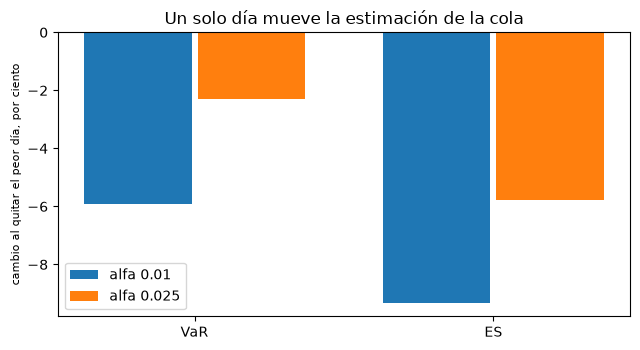

In [5]:
# Quitar el peor día y recalcular VaR y ES: cuánto mueve una sola observación la estimación de la cola
trimmed = np.delete(y, int(np.argmin(y)))
shift = {}
for alpha in (0.01, 0.025):
    var_all, es_all = var_es_from_sample(y, alpha)
    var_cut, es_cut = var_es_from_sample(trimmed, alpha)
    shift[alpha] = (100 * (var_cut / var_all - 1), 100 * (es_cut / es_all - 1))
    print(f"alfa {alpha}: VaR {shift[alpha][0]:.1f}% | ES {shift[alpha][1]:.1f}%")

fig, ax = plt.subplots(figsize=(6.5, 3.6))
for offset, alpha in enumerate(shift):
    ax.bar(np.arange(2) + 0.38 * offset - 0.19, shift[alpha], width=0.36, label=f"alfa {alpha}")
ax.set_xticks(np.arange(2))
ax.set_xticklabels(["VaR", "ES"])
ax.set_ylabel("cambio al quitar el peor día, por ciento", fontsize=8)
ax.set_title("Un solo día mueve la estimación de la cola")
ax.legend()
fig.tight_layout()
plt.show()

Las barras muestran el cambio porcentual de la estimación cuando se quita de la muestra el peor día del año. La ES se mueve más que el VaR en los dos niveles, y el nivel de 1 por ciento se mueve más que el de 2,5 por ciento, porque cuanto más chica es la cola, menos días promedia. La figura no dice qué estimación es la correcta, solo que una estimación apoyada en dos o tres días es frágil; la misma fragilidad está detrás de toda prueba retrospectiva de un pronóstico al 1 por ciento sobre un año de datos.

### Paso 3: un pronóstico de simulación histórica a un paso

Un pronóstico es una afirmación hecha **antes** del día al que se refiere. La simulación histórica toma los retornos de los últimos $W$ días como los escenarios de mañana y lee el VaR y la ES de esa muestra. Para el pronóstico del día $t$, la función `historical_var_es(returns, alpha, window)` del motor debe recibir solo los retornos con fecha anterior a $t$, el más reciente al final; entregarle el propio día $t$ volvería inútil la prueba retrospectiva.

El escalón `hs-250` de Contraste usa 250 días, y su primera ventana de estimación termina antes de que el archivo empiece. El archivo tiene solo 251 días, así que aquí usamos una ventana más corta, $W = 100$, y pronosticamos los últimos 151 días con retornos dentro del archivo. La ventana es una elección de este notebook; el `hs-250` versionado se lee en el paso 5.

alfa 0.01: días pronosticados 151
  excepciones 1 | esperadas 1.51
alfa 0.025: días pronosticados 151
  excepciones 4 | esperadas 3.78


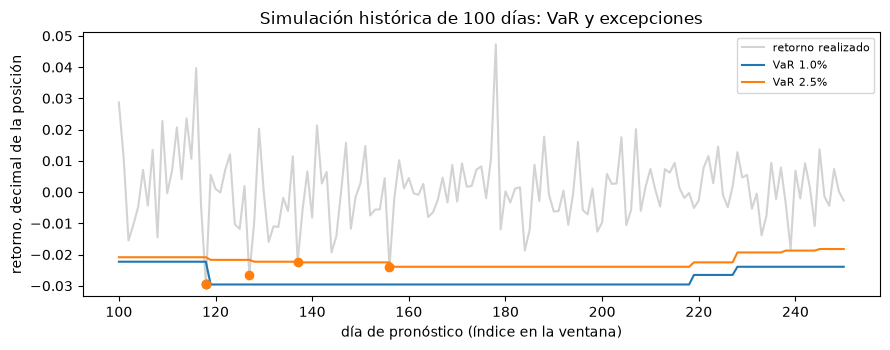

In [6]:
# Pronosticar cada día solo con los W retornos anteriores (sin mirar hacia adelante), marcar las excepciones
# y dibujar la trayectoria del VaR
from riskvalidation.market.historical import historical_var_es

W = 100
days = np.arange(W, n)
forecasts = {}
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(days, y[W:], color="lightgrey", label="retorno realizado")
for alpha in (0.01, 0.025):
    var_path = np.array([historical_var_es(y[:t], alpha, W)[0] for t in range(W, n)])
    flags = y[W:] < var_path
    forecasts[alpha] = flags
    line, = ax.plot(days, var_path, label=f"VaR {alpha:.1%}")
    ax.scatter(days[flags], y[W:][flags], color=line.get_color(), zorder=3)
    print(f"alfa {alpha}: días pronosticados {flags.size}")
    print(f"  excepciones {int(flags.sum())} | esperadas {alpha * flags.size:.2f}")
ax.set_xlabel("día de pronóstico (índice en la ventana)")
ax.set_ylabel("retorno, decimal de la posición")
ax.set_title("Simulación histórica de 100 días: VaR y excepciones")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

La línea es el VaR que la ventana de 100 días dio cada mañana y los puntos son los días en que el retorno realizado cayó por debajo de él. El nivel de 1 por ciento tiene su única excepción en el día 118, el peor retorno del archivo; desde la mañana siguiente ese día está en la ventana y las dos líneas de VaR bajan, y 100 días después sale de la ventana y vuelven a subir. Un VaR histórico reacciona entonces solo después de la pérdida y se mantiene conservador exactamente mientras la pérdida sigue dentro de la ventana; la cantidad de puntos es lo que prueba el paso siguiente.

### Paso 4: la prueba de Kupiec sobre el conteo de excepciones

Si el VaR es correcto, cada día tiene probabilidad $\alpha$ de una excepción, de manera independiente, de modo que el conteo $x$ en $T$ días es binomial con parámetros $T$ y $\alpha$. Kupiec (1995) compara la proporción observada $\hat\pi = x/T$ con $\alpha$ mediante una razón de verosimilitud:

$$LR_{POF} = -2\ln\frac{(1-\alpha)^{T-x}\,\alpha^{x}}{(1-\hat\pi)^{T-x}\,\hat\pi^{x}} \;\xrightarrow{d}\; \chi^2_1$$

La función `kupiec_pof(exceedances, alpha)` del motor devuelve este estadístico, su valor p asintótico y, en `metric`, el valor p binomial **exacto**, que importa cuando el conteo esperado es pequeño (la ley asintótica es mala guía con un conteo esperado de 1,5). Su luz es una compuerta interna de Contraste sobre el valor p asintótico (ámbar bajo 0,10, roja bajo 0,05), no un umbral regulatorio. La celda siguiente la ejecuta sobre los dos pronósticos del paso 3.

In [7]:
# Prueba de proporción de fallas de Kupiec sobre las banderas del paso 3: estadístico, valores p asintótico
# y exacto, luz
from riskvalidation.validation.market import kupiec_pof

for alpha, flags in forecasts.items():
    result = kupiec_pof(flags, alpha, model_id="hs-100")
    expected = result.extras["expected_events"]
    print(f"alfa {alpha}: excepciones {result.n_events} / {result.n} | esperadas {expected:.2f}")
    print(f"  LR_POF {result.statistic:.4f} | p asintótico {result.p_value:.4f} | p exacto {result.metric:.4f}")
    print(f"  luz: {LIGHT[result.light.value]}")

alfa 0.01: excepciones 1 / 151 | esperadas 1.51
  LR_POF 0.1975 | p asintótico 0.6567 | p exacto 1.0000
  luz: verde
alfa 0.025: excepciones 4 / 151 | esperadas 3.78
  LR_POF 0.0135 | p asintótico 0.9075 | p exacto 0.7927
  luz: verde


### Paso 5: el pronóstico versionado en el año de crisis

El pronóstico `hs-250` versionado por Contraste para la misma posición en euros permite repetir el conteo sobre la escalera real. El VaR versionado es un número de pérdida positivo, así que un día es una excepción cuando la pérdida realizada está **por encima** de él. La celda reconstruye las banderas desde las pérdidas realizadas de este archivo, corre Kupiec sobre ellas en los dos niveles y cuenta cuántas excepciones caen dentro de los primeros 100 días, que el pronóstico del paso 3 no puntúa.

In [8]:
# Reconstruir las banderas de excepción del pronóstico hs-250 versionado desde las pérdidas realizadas y
# correr Kupiec sobre ellas
for level in hs250["by_level"]:
    alpha = level["alpha"]
    flags = loss > np.array(level["var"])
    result = kupiec_pof(flags, alpha, model_id="hs-250")
    early = int(np.sum(np.flatnonzero(flags) < W))
    expected = level["expected_exceedances"]
    print(f"alfa {alpha}: excepciones {int(flags.sum())} de {flags.size} | esperadas {expected:.2f}")
    print(f"  p {result.p_value:.6f} | luz {LIGHT[result.light.value]} | excepciones antes del día {W}: {early}")

alfa 0.01: excepciones 10 de 251 | esperadas 2.51
  p 0.000330 | luz rojo | excepciones antes del día 100: 6
alfa 0.025: excepciones 13 de 251 | esperadas 6.28
  p 0.017215 | luz rojo | excepciones antes del día 100: 9


### Paso 6: una ventana cuyos retornos no se versionan

La ventana tranquila contiene un retorno de Kenneth French, así que sus pérdidas realizadas se retienen. El artefacto guarda igual, para cada modelo y nivel, los **días en que la pérdida superó al VaR** (`exceedance_days`, índices sobre las 750 fechas de pronóstico) y la trayectoria del VaR. Eso es todo lo que necesitan las pruebas de excepciones: una prueba del conteo lee banderas, no retornos. Reconstruimos las 750 banderas desde los días guardados, las contamos y volvemos a correr Kupiec.

In [9]:
# Reconstruir las 750 banderas de la ventana tranquila desde los días de excepción guardados y correr Kupiec
# sobre ellas
calm_hs = {m["model_id"]: m for m in calm["outputs"]["models"]}["hs-250"]
dates = calm["outputs"]["grid"]["dates"]
for level in calm_hs["by_level"]:
    alpha = level["alpha"]
    flags = np.zeros(level["n_scored"], dtype=bool)
    flags[level["exceedance_days"]] = True
    result = kupiec_pof(flags, alpha, model_id="hs-250")
    expected = level["expected_exceedances"]
    print(f"alfa {alpha}: {flags.size} días | excepciones {int(flags.sum())} | esperadas {expected:.2f}")
    print(f"  primera {dates[level['exceedance_days'][0]]}, última {dates[level['exceedance_days'][-1]]}")
    print(f"  p {result.p_value:.6f} | p exacto {result.metric:.4f} | luz {LIGHT[result.light.value]}")

alfa 0.01: 750 días | excepciones 9 | esperadas 7.50
  primera 2004-03-10, última 2006-06-05
  p 0.593559 | p exacto 0.5777 | luz verde
alfa 0.025: 750 días | excepciones 22 | esperadas 18.75
  primera 2004-01-28, última 2006-07-05
  p 0.459214 | p exacto 0.4127 | luz verde


La última celda dibuja las dos ventanas. A la izquierda, la posición en euros: la pérdida realizada de cada día (barras), el VaR y la ES de `hs-250` versionados al 1 por ciento (líneas) y los días de excepción (puntos rojos). A la derecha, la ventana tranquila: la trayectoria del VaR versionado al 1 por ciento y los días en que la pérdida lo superó. Los dos paneles tienen escalas distintas a propósito: son carteras distintas.

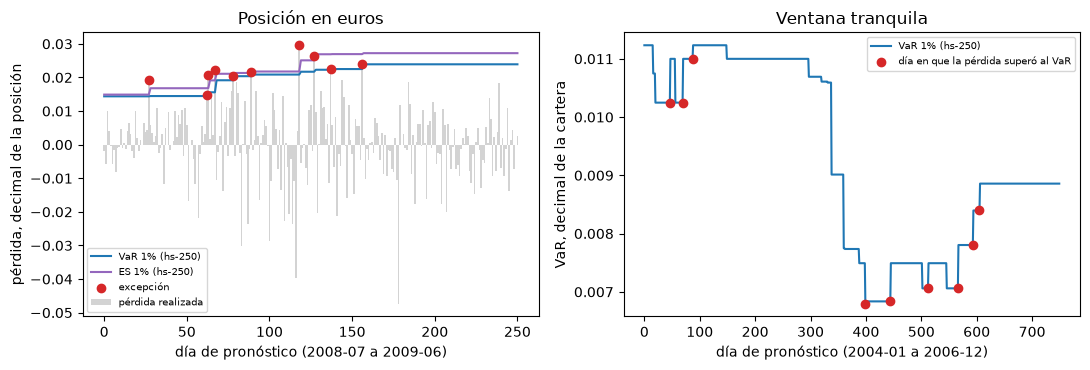

In [10]:
# Dibujar las dos ventanas: la posición en euros frente a su pronóstico hs-250 versionado y la trayectoria
# del VaR de la ventana tranquila con sus excepciones
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.8))
day = np.arange(loss.size)
var_fx, es_fx = np.array(level_1pct["var"]), np.array(level_1pct["es"])
hit = loss > var_fx
left.bar(day, loss, color="lightgrey", width=1.0, label="pérdida realizada")
left.plot(day, var_fx, color="tab:blue", label="VaR 1% (hs-250)")
left.plot(day, es_fx, color="tab:purple", label="ES 1% (hs-250)")
left.scatter(day[hit], loss[hit], color="tab:red", zorder=3, label="excepción")
left.set_xlabel("día de pronóstico (2008-07 a 2009-06)")
left.set_ylabel("pérdida, decimal de la posición")
left.set_title("Posición en euros")
left.legend(fontsize=7)

calm_level = calm_hs["by_level"][0]
var_calm = np.array(calm_level["var"])
right.plot(var_calm, color="tab:blue", label="VaR 1% (hs-250)")
right.scatter(calm_level["exceedance_days"], var_calm[calm_level["exceedance_days"]], color="tab:red", zorder=3,
              label="día en que la pérdida superó al VaR")
right.set_xlabel("día de pronóstico (2004-01 a 2006-12)")
right.set_ylabel("VaR, decimal de la cartera")
right.set_title("Ventana tranquila")
right.legend(fontsize=7)
fig.tight_layout()
plt.show()

En el panel izquierdo el VaR y la ES de la ventana versionada de 250 días se mantienen planos durante largos tramos y suben solo después de un punto rojo: las diez excepciones caen en los primeros 160 días del año, y cada una eleva el pronóstico que la pérdida siguiente debe superar. En el panel derecho tres excepciones llegan temprano, con el VaR sobre 0,010, y seis después del día 395, cuando un año de calma bajó el VaR a sus niveles más bajos, entre 0,007 y 0,009. Los paneles usan escalas distintas a propósito, pues son carteras distintas; lo que muestran juntos es que un VaR histórico protege menos justo después de los mercados tranquilos, y que el conteo solo no dice si las excepciones vienen en racimos, cosa que prueba el notebook siguiente.

## Resultados

**Respuesta:** No. Al nivel de cola 0,01 la simulación histórica versionada superó su VaR en 10 de 251 días donde se esperaban 2,51, y Kupiec rechaza un pronóstico correcto con un valor p de 0,000330 (rojo); al nivel 0,025 el conteo es 13 contra 6,28 (p 0,017215, rojo). La simulación de 100 días del paso 3, puntuada sobre los últimos 151 días más tranquilos, tuvo 1 excepción contra 1,51 esperadas y pasa (p 0,6567).

- **Convención.** El VaR versionado es un número de pérdida positivo (0,01438435 en los primeros días de la ventana en euros) y el motor lo guarda como retorno negativo (-0,01438435); la segunda función devuelve el número versionado. Un informe que no dice qué convención usa es ambiguo por un signo.
- **La cola se apoya en pocos días.** Sobre los 251 retornos el VaR de 0,01 es 0,023915 de la posición y la ES 0,027216, y los pesos de la cola son 1, 1 y 0,51, de modo que tres días sostienen la estimación. Quitar el peor día mueve el VaR en -5,9% y la ES en -9,3% a 0,01, y en -2,3% y -5,8% a 0,025: la ES es la más frágil de las dos, y una ventana corta la hace más frágil aún.
- **Un primer conteo.** La simulación de 100 días tuvo 1 excepción a 0,01 (1,51 esperadas) y 4 a 0,025 (3,78 esperadas), y Kupiec no rechaza (p 0,6567 y 0,9075). Con una excepción el valor p exacto (1,0000) y el asintótico (0,6567) están lejos, el caso de conteo pequeño que el motor informa junto al valor asintótico.
- **El año de crisis.** De las 10 excepciones versionadas a 0,01, 6 caen en los primeros 100 días, que el pronóstico del paso 3 nunca puntúa; a 0,025, 9 de 13. Los dos conteos se hacen sobre días distintos y no se pueden comparar uno a uno.
- **La ventana tranquila.** El mismo escalón tiene 9 excepciones a 0,01 en 750 días (7,50 esperadas, p 0,593559, verde) y 22 a 0,025 (18,75 esperadas, p 0,459214, verde). Las banderas reconstruidas solo desde los días de excepción guardados bastan para la prueba del conteo, de modo que una ventana cuyos retornos se retienen por licencia se puede igual someter a la prueba del conteo.

Lo que este notebook no muestra: la dependencia entre excepciones (notebook 03), el pronóstico de ES (notebook 04), los otros estimadores (notebook 02) ni cómo ordenarlos (notebook 05).

## Resumen

- El motor guarda VaR y ES en la convención de retornos (números negativos) y los documentos versionados guardan pérdidas positivas; `to_loss_numbers` y `from_loss_numbers` son el único lugar donde cambia el signo.
- Un VaR muestral es un estadístico de orden y la ES un promedio de cola con peso fraccionario en la última observación; al 1 por ciento sobre unos 250 días se apoyan en dos o tres días, así que una observación los mueve de forma visible.
- Un pronóstico se hace con información fechada antes del día al que se refiere. Contar cuántas veces la pérdida realizada lo superó, frente a las $\alpha T$ esperadas, es la primera prueba retrospectiva, y la prueba de Kupiec dice si el conteo es compatible con el nivel nominal; con un conteo esperado pequeño, lee el valor p exacto junto al asintótico.
- Las pruebas de excepciones necesitan banderas, no retornos: una ventana cuyos retornos se retienen por licencia se puede igual someter a prueba retrospectiva desde los días de excepción guardados.

**Qué probar después.** Cambia `W` en el paso 3 a 60 y a 150 y mira el conteo de excepciones y el valor p de Kupiec; luego continúa con el notebook 02, que recorre toda la escalera de estimadores.

## Referencias

- Kupiec, P. H. (1995), Techniques for verifying the accuracy of risk measurement models, Journal of Derivatives 3(2). https://doi.org/10.3905/jod.1995.407942
- Patton, A. J., Ziegel, J. F. y Chen, R. (2019), Dynamic semiparametric models for expected shortfall (and value-at-risk), Journal of Econometrics 211(2); la convención de retornos, ecuaciones 1 y 2. https://arxiv.org/abs/1707.05108
- Comité de Supervisión Bancaria de Basilea (1996), Supervisory framework for the use of backtesting in conjunction with the internal models approach to market risk capital requirements. https://www.bis.org/publ/bcbs22.htm
- Pritsker, M. (2001), The hidden dangers of historical simulation, Federal Reserve Board FEDS 2001-27. https://www.federalreserve.gov/Pubs/feds/2001/200127/200127pap.pdf
- Los tipos de cambio H.10 de la Reserva Federal y la biblioteca de datos de Kenneth French son las fuentes de las dos ventanas; solo se versionan valores derivados (véase la página del caso).